Pembersihan data selesai.

Threshold Beresiko (10%)    : 81.61
Threshold Sangat Aman (20%) : 85.66
status_siswa
Aman           176
Sangat Aman     51
Beresiko        26
Name: count, dtype: int64
status_siswa
Aman           69.565217
Sangat Aman    20.158103
Beresiko       10.276680
Name: proportion, dtype: float64
Distribusi data training:
Counter({'Aman': 140, 'Sangat Aman': 41, 'Beresiko': 21})

Distribusi data testing:
Counter({'Aman': 36, 'Sangat Aman': 10, 'Beresiko': 5})


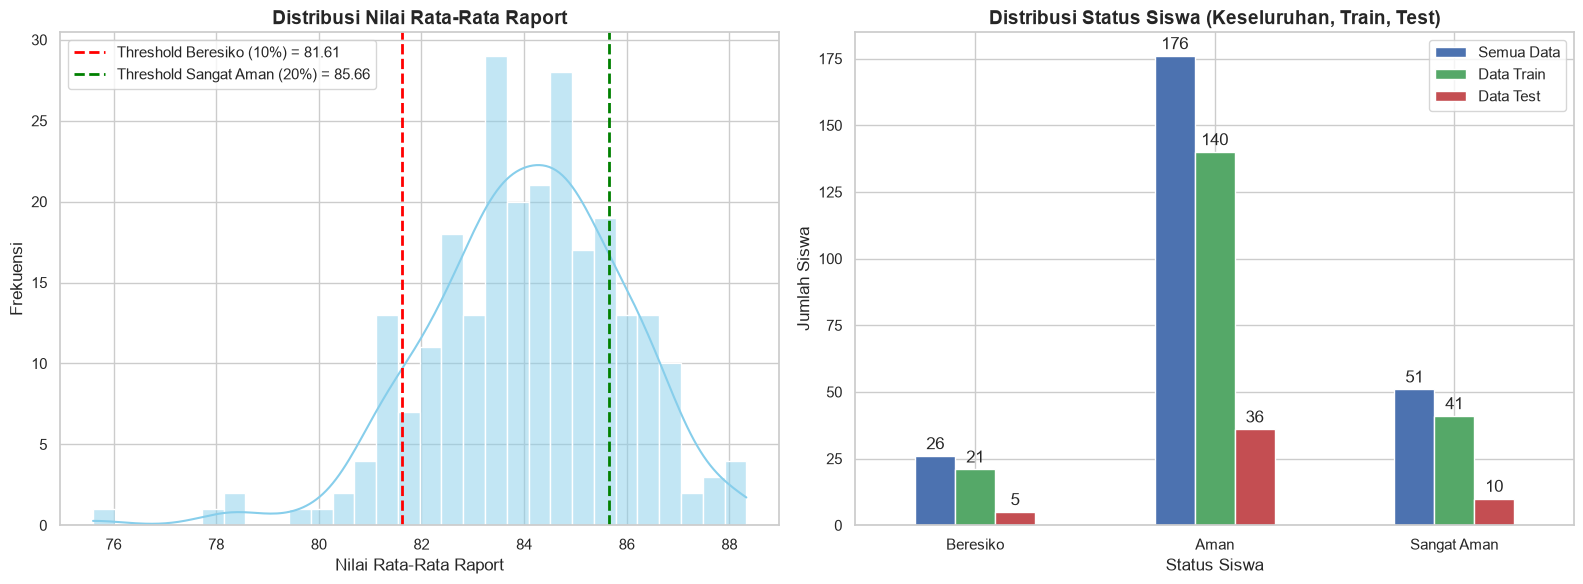


INFORMASI VARIABEL INPUT (FITUR)
Total jumlah kolom pada DataFrame setelah One-Hot Encoding: 23
Total variabel input (X) untuk model: 22

Daftar variabel input (X):
1. presentase_kehadiran
2. libur_tanpa_keterangan
3. skor_skill_level
4. jam_belajar_per_hari
5. jam_tidur
6. screen_time
7. industry_readiness
8. skor_time_management
9. motivasi_akademik
10. pendidikan_terakhir_orang_tua_SMA/SMK
11. pendidikan_terakhir_orang_tua_SMP
12. pendidikan_terakhir_orang_tua_Sarjana
13. rata_rata_pemasukan_keluarga_5 - 10 Juta
14. rata_rata_pemasukan_keluarga_< 2 Juta
15. rata_rata_pemasukan_keluarga_> 10 Juta
16. kerja_sampingan_Ya
17. kompetensi_skill_level_Rendah
18. kompetensi_skill_level_Tinggi
19. study_environment_Kondusif
20. study_environment_Kurang Kondusif
21. stress_level_Rendah
22. stress_level_Sedang



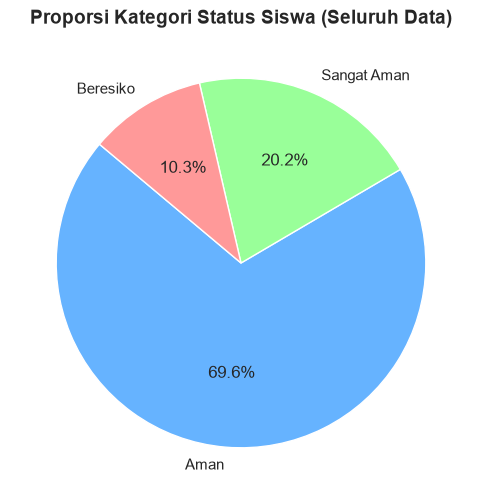

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, accuracy_score, mean_absolute_error, r2_score,
    f1_score, confusion_matrix
)
from sklearn.neighbors import NearestNeighbors
from imblearn.over_sampling import SMOTE
from collections import Counter
import shap
import joblib
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 1. Load Data & Pembersihan
# ==========================================
df = pd.read_csv('data_clean.csv', dtype={'nisn': str})
df = df.dropna(how='all').reset_index(drop=True)

print("Pembersihan data selesai.\n")

# Simpan target numerik asli
y_numerik = df['nilai_rata_rata_raport'].values

# Hitung threshold berdasarkan persentil
p10 = np.percentile(df['nilai_rata_rata_raport'], 10)   # 10% terbawah
p80 = np.percentile(df['nilai_rata_rata_raport'], 80)   # 20% teratas

print(f"Threshold Beresiko (10%)    : {p10:.2f}")
print(f"Threshold Sangat Aman (20%) : {p80:.2f}")

def categorize_score(score):
    if score <= p10:
        return 'Beresiko'
    elif score >= p80:
        return 'Sangat Aman'
    else:
        return 'Aman'

df['status_siswa'] = df['nilai_rata_rata_raport'].apply(categorize_score)

print(df['status_siswa'].value_counts())
print(df['status_siswa'].value_counts(normalize=True) * 100)

# ==========================================
# Hapus kolom tidak relevan
# ==========================================
kolom_dihapus = [
    'nisn',
    'nama_siswa',
    'email',
    'nilai_rata_rata_raport',
    'gender',
    'jurusan',
]
df = df.drop(columns=kolom_dihapus, errors='ignore')

# ==========================================
# One-Hot Encoding
# ==========================================
kolom_kategori = df.select_dtypes(include=['object']).drop(columns=['status_siswa']).columns
df = pd.get_dummies(df, columns=kolom_kategori, drop_first=True)

X = df.drop(columns=['status_siswa'])
y = df['status_siswa']

# ==========================================
# Train-Test Split
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

y_train_num = y_numerik[X_train.index]
y_test_num = y_numerik[X_test.index]

print("Distribusi data training:")
print(Counter(y_train))
print("\nDistribusi data testing:")
print(Counter(y_test))

# ==========================================
# VISUALISASI DISTRIBUSI DATA
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ------------------------------------------
# 1. Plot Distribusi Nilai Rata-rata Numerik
# ------------------------------------------
sns.histplot(y_numerik, bins=30, kde=True, color='skyblue', ax=axes[0])
axes[0].axvline(p10, color='red', linestyle='--', linewidth=2, label=f'Threshold Beresiko (10%) = {p10:.2f}')
axes[0].axvline(p80, color='green', linestyle='--', linewidth=2, label=f'Threshold Sangat Aman (20%) = {p80:.2f}')

axes[0].set_title('Distribusi Nilai Rata-Rata Raport', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Nilai Rata-Rata Raport', fontsize=12)
axes[0].set_ylabel('Frekuensi', fontsize=12)
axes[0].legend()

# ------------------------------------------
# 2. Plot Distribusi Kategori (Status Siswa)
# ------------------------------------------
# Membuat DataFrame sederhana untuk plotting bar chart per split data
dist_df = pd.DataFrame({
    'Semua Data': df['status_siswa'].value_counts(),
    'Data Train': y_train.value_counts(),
    'Data Test': y_test.value_counts()
}).fillna(0)

# Reorder index agar urutannya konsisten
kategori_order = ['Beresiko', 'Aman', 'Sangat Aman']
dist_df = dist_df.reindex(kategori_order)

dist_df.plot(kind='bar', ax=axes[1], color=['#4C72B0', '#55A868', '#C44E52'])

axes[1].set_title('Distribusi Status Siswa (Keseluruhan, Train, Test)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Status Siswa', fontsize=12)
axes[1].set_ylabel('Jumlah Siswa', fontsize=12)
axes[1].tick_params(axis='x', rotation=0)

# Menambahkan anotasi angka di atas bar
for p in axes[1].patches:
    axes[1].annotate(format(p.get_height(), '.0f'), 
                   (p.get_x() + p.get_width() / 2., p.get_height()), 
                   ha = 'center', va = 'center', 
                   xytext = (0, 8), 
                   textcoords = 'offset points')

plt.tight_layout()
plt.show()

print("\n" + "="*40)
print("INFORMASI VARIABEL INPUT (FITUR)")
print("="*40)
print(f"Total jumlah kolom pada DataFrame setelah One-Hot Encoding: {df.shape[1]}")
print(f"Total variabel input (X) untuk model: {X.shape[1]}\n")

print("Daftar variabel input (X):")
for i, col in enumerate(X.columns, 1):
    print(f"{i}. {col}")
print("="*40 + "\n")

# ==========================================
# (Opsional) Plot Proporsi (Pie Chart)
# ==========================================
plt.figure(figsize=(8, 6))
plt.pie(df['status_siswa'].value_counts(), 
        labels=df['status_siswa'].value_counts().index, 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=['#66b3ff','#99ff99','#ff9999'])
plt.title('Proporsi Kategori Status Siswa (Seluruh Data)', fontsize=14, fontweight='bold')
plt.show()

In [77]:
# ==========================================
# 2. Fungsi Eksperimen
# ==========================================
def run_experiment(use_scaling, X_tr, X_te, y_tr, y_te, y_tr_num, y_te_num, exp_name):
    print(f"\n{'='*60}")
    print(f"Menjalankan: {exp_name}")
    print(f"{'='*60}")

    if use_scaling:
        scaler = StandardScaler()
        X_train_used = scaler.fit_transform(X_tr)
        X_test_used = scaler.transform(X_te)
    else:
        scaler = None
        X_train_used = X_tr.values
        X_test_used = X_te.values

    # SMOTE auto
    min_samples = min(Counter(y_tr).values())
    k_neighbors = min(5, min_samples - 1) if min_samples > 1 else 1
    smote = SMOTE(sampling_strategy='auto', random_state=42, k_neighbors=k_neighbors)
    X_train_res, y_train_res = smote.fit_resample(X_train_used, y_tr)

    # Target numerik sintetis
    nn = NearestNeighbors(n_neighbors=5)
    nn.fit(X_train_used)
    _, indices = nn.kneighbors(X_train_res)
    y_train_num_used = np.mean(y_tr_num[indices], axis=1)

    # Tuning Random Forest
    param_dist = {
        'n_estimators': [50, 100, 200, 300, 500],
        'max_depth': [3, 5, 10, 15, 20, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2', None],
        'bootstrap': [True, False]
    }
    rf_clf = RandomForestClassifier(random_state=42)
    random_search = RandomizedSearchCV(
        rf_clf, param_dist, n_iter=30, cv=5,
        scoring='f1_macro', random_state=42, n_jobs=-1, verbose=0
    )
    random_search.fit(X_train_res, y_train_res)
    best_clf = random_search.best_estimator_
    print(f"Best Parameters: {random_search.best_params_}")

    y_pred = best_clf.predict(X_test_used)
    acc = accuracy_score(y_te, y_pred)
    f1_macro = f1_score(y_te, y_pred, average='macro')
    print(f"\nAkurasi: {acc*100:.2f}% | F1-Macro: {f1_macro:.4f}")
    print(classification_report(y_te, y_pred))

    # Regresi
    rf_reg = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42)
    rf_reg.fit(X_train_res, y_train_num_used)
    y_pred_num = rf_reg.predict(X_test_used)
    mae = mean_absolute_error(y_te_num, y_pred_num)
    r2 = r2_score(y_te_num, y_pred_num)
    print(f"Regresi: MAE={mae:.3f}, R²={r2:.3f}")

    return {
        'name': exp_name,
        'model': best_clf,
        'accuracy': acc,
        'f1_macro': f1_macro,
        'mae': mae,
        'r2': r2,
        'X_test_used': X_test_used,
        'y_test': y_te,
        'y_pred': y_pred,
        'feature_names': X_tr.columns.tolist(),
        'scaler': scaler
    }

# Jalankan dua eksperimen
res_scaled = run_experiment(True, X_train, X_test, y_train, y_test, y_train_num, y_test_num, "Dengan StandardScaler")
res_raw = run_experiment(False, X_train, X_test, y_train, y_test, y_train_num, y_test_num, "Tanpa StandardScaler")

# Pilih model terbaik (berdasarkan F1-Macro)
best = res_scaled if res_scaled['f1_macro'] >= res_raw['f1_macro'] else res_raw
print(f"\nModel terbaik dipilih: {best['name']} (F1={best['f1_macro']:.4f})")


Menjalankan: Dengan StandardScaler
Best Parameters: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 15, 'bootstrap': True}

Akurasi: 86.27% | F1-Macro: 0.7528
              precision    recall  f1-score   support

        Aman       0.85      0.97      0.91        36
    Beresiko       1.00      0.40      0.57         5
 Sangat Aman       0.88      0.70      0.78        10

    accuracy                           0.86        51
   macro avg       0.91      0.69      0.75        51
weighted avg       0.87      0.86      0.85        51

Regresi: MAE=1.006, R²=0.392

Menjalankan: Tanpa StandardScaler
Best Parameters: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': None, 'bootstrap': False}

Akurasi: 84.31% | F1-Macro: 0.7343
              precision    recall  f1-score   support

        Aman       0.85      0.94      0.89        36
    Beresiko       1.00      0.40      0.5

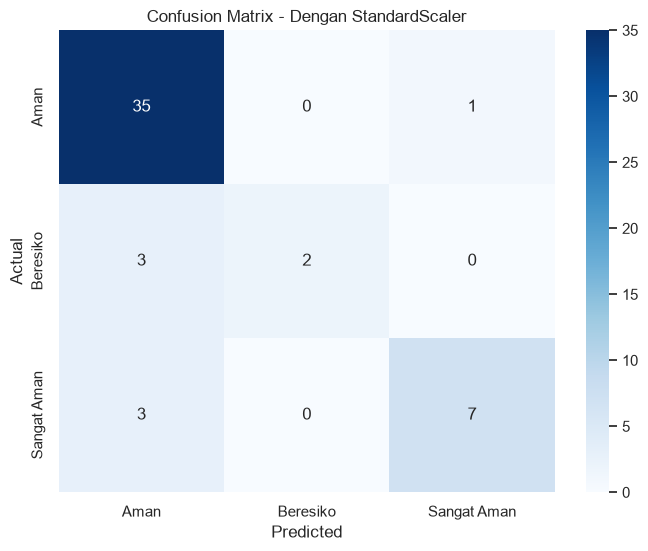


Distribusi data test:
  Aman: 36 sampel
  Beresiko: 5 sampel
  Sangat Aman: 10 sampel

Total misklasifikasi: 7 dari 51 data uji


In [78]:
# ==========================================
# 3. HEATMAP CONFUSION MATRIX & DISTRIBUSI DATA
# ==========================================
cm = confusion_matrix(best['y_test'], best['y_pred'], labels=best['model'].classes_)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=best['model'].classes_,
            yticklabels=best['model'].classes_)
plt.title(f'Confusion Matrix - {best["name"]}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

unique, counts = np.unique(best['y_test'], return_counts=True)
print("\nDistribusi data test:")
for cls, cnt in zip(unique, counts):
    print(f"  {cls}: {cnt} sampel")

misclassified = (best['y_test'] != best['y_pred']).sum()
print(f"\nTotal misklasifikasi: {misclassified} dari {len(best['y_test'])} data uji")


Men-generate SHAP values...


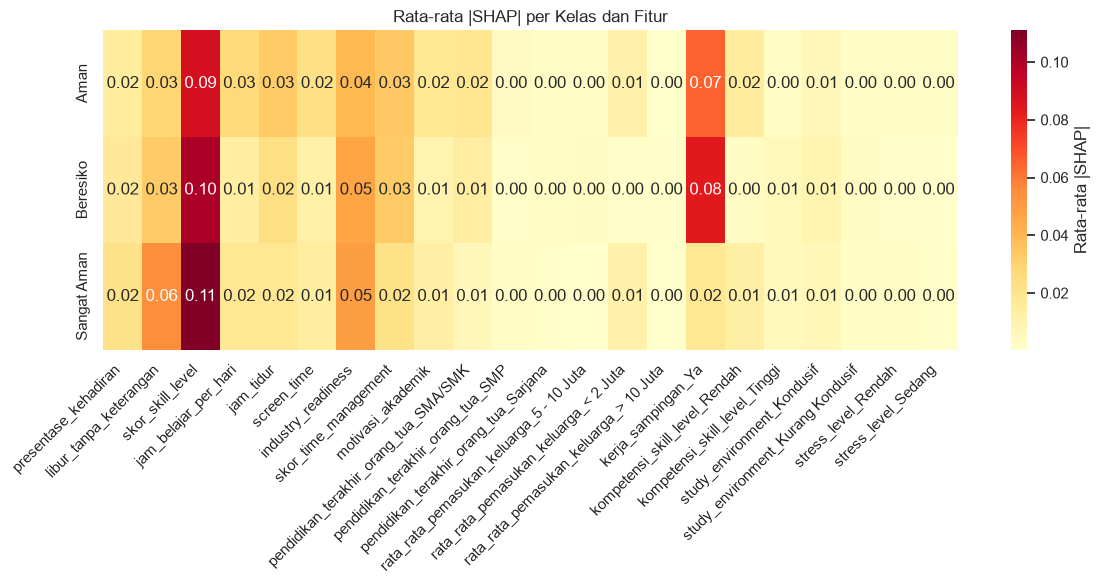


--- Faktor Paling Berpengaruh per Kelas (Top 5) ---

Kelas: Aman
  1. skor_skill_level (|SHAP|=0.0893)
  2. kerja_sampingan_Ya (|SHAP|=0.0650)
  3. industry_readiness (|SHAP|=0.0394)
  4. skor_time_management (|SHAP|=0.0338)
  5. jam_tidur (|SHAP|=0.0331)

Kelas: Beresiko
  1. skor_skill_level (|SHAP|=0.1009)
  2. kerja_sampingan_Ya (|SHAP|=0.0834)
  3. industry_readiness (|SHAP|=0.0468)
  4. libur_tanpa_keterangan (|SHAP|=0.0331)
  5. skor_time_management (|SHAP|=0.0328)

Kelas: Sangat Aman
  1. skor_skill_level (|SHAP|=0.1109)
  2. libur_tanpa_keterangan (|SHAP|=0.0556)
  3. industry_readiness (|SHAP|=0.0493)
  4. skor_time_management (|SHAP|=0.0222)
  5. presentase_kehadiran (|SHAP|=0.0217)


In [79]:
# ==========================================
# 4. ANALISIS SHAP PER KELAS (DIPERBAIKI)
# ==========================================
print("\nMen-generate SHAP values...")
explainer = shap.TreeExplainer(best['model'])
shap_values_raw = explainer.shap_values(best['X_test_used'])

# Deteksi format output SHAP (list vs array 3D) dan konversi ke list of arrays per kelas
if isinstance(shap_values_raw, list):
    # Versi lama: list dengan panjang = jumlah kelas, tiap elemen shape (n_samples, n_features)
    shap_per_class = shap_values_raw
    n_classes = len(shap_per_class)
else:
    # Versi baru: array 3D (n_samples, n_features, n_classes)
    n_classes = shap_values_raw.shape[2]
    shap_per_class = [shap_values_raw[:, :, i] for i in range(n_classes)]

n_features = best['X_test_used'].shape[1]
class_names = best['model'].classes_.tolist()

# Hitung rata-rata |SHAP| per fitur per kelas
mean_abs_shap = np.zeros((n_classes, n_features))
for i in range(n_classes):
    mean_abs_shap[i, :] = np.abs(shap_per_class[i]).mean(axis=0)

# ---- Heatmap rata-rata |SHAP| ----
plt.figure(figsize=(12, 6))
sns.heatmap(mean_abs_shap, annot=True, fmt='.2f', cmap='YlOrRd',
            xticklabels=best['feature_names'],
            yticklabels=class_names,
            cbar_kws={'label': 'Rata-rata |SHAP|'})
plt.title('Rata-rata |SHAP| per Kelas dan Fitur')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ---- Faktor paling berpengaruh per kelas ----
print("\n--- Faktor Paling Berpengaruh per Kelas (Top 5) ---")
for i, cls in enumerate(class_names):
    importance = mean_abs_shap[i, :]
    sorted_idx = np.argsort(importance)[::-1]
    print(f"\nKelas: {cls}")
    for rank, idx in enumerate(sorted_idx[:5], 1):
        print(f"  {rank}. {best['feature_names'][idx]} (|SHAP|={importance[idx]:.4f})")

In [80]:
# ==========================================
# EXPORT MODEL & PREPROCESSOR
# ==========================================
print("\nMenyimpan model dan preprocessor...")

# 1. Simpan model classifier terbaik
joblib.dump(best['model'], 'rf_classifier_best.pkl')
print("✓ rf_classifier_best.pkl")

# 2. Simpan scaler (jika ada)
if best['scaler'] is not None:
    joblib.dump(best['scaler'], 'scaler.pkl')
    print("✓ scaler.pkl")
else:
    # Jika tanpa scaler, kita tetap bisa menyimpan placeholder atau skip
    print("! Tidak ada scaler (model dilatih tanpa StandardScaler)")

# 3. Simpan daftar fitur (urutan kolom yang diharapkan model)
joblib.dump(best['feature_names'], 'feature_names.pkl')
print("✓ feature_names.pkl")

# 4. (Opsional) Simpan juga kategori asli untuk one-hot encoding
# Karena pd.get_dummies sulit direproduksi persis, sebaiknya gunakan OneHotEncoder.
# Untuk sementara, kita simpan semua kolom kategorik dan nilai dummies dari data training
# agar nanti bisa dipakai untuk menyamakan kolom data baru.
train_cols = X_train.columns.tolist()
joblib.dump(train_cols, 'train_columns.pkl')
print("✓ train_columns.pkl (untuk menyamakan fitur data baru)")

print("\nExport selesai. File .pkl siap digunakan untuk prediksi.")
print("Catatan: Untuk prediksi data baru, pastikan melakukan one-hot encoding yang sama")
print("dengan data training, lalu pilih hanya kolom yang sesuai dengan train_columns.")


Menyimpan model dan preprocessor...
✓ rf_classifier_best.pkl
✓ scaler.pkl
✓ feature_names.pkl
✓ train_columns.pkl (untuk menyamakan fitur data baru)

Export selesai. File .pkl siap digunakan untuk prediksi.
Catatan: Untuk prediksi data baru, pastikan melakukan one-hot encoding yang sama
dengan data training, lalu pilih hanya kolom yang sesuai dengan train_columns.


In [ ]:
# ============================================================
# 5. PERBANDINGAN NILAI AKTUAL, NILAI PREDIKSI, DAN KELAS MODEL
# ============================================================
# Menggunakan data testing yang sama dengan pengujian classifier
# (X_test dan y_test; test_size=0.20, random_state=42, stratify=y).
#
# Catatan:
# - "Kelas seharusnya" ditentukan dari nilai rapor aktual dan threshold p10/p80.
# - "Kelas dari model" berasal dari Random Forest Classifier terbaik (best['model']).
# - Random Forest Regressor dilatih ulang dengan konfigurasi dan prosedur target
#   numerik yang sama seperti di run_experiment, karena objek regresi dan
#   prediksi numeriknya belum disimpan ke dalam dictionary hasil eksperimen.
# - Nomor baris CSV = indeks record (0-based) + 2 (baris header adalah baris 1).

# Pastikan urutan data uji sama dengan urutan prediksi classifier terpilih
test_index = best['y_test'].index
assert list(test_index) == list(X_test.index), (
    "Urutan indeks y_test dan X_test tidak sama. Periksa kembali proses split."
)

# 1. Siapkan fitur train dan test dengan preprocessing eksperimen terbaik
if best['scaler'] is not None:
    X_train_reg_used = best['scaler'].transform(X_train)
    X_test_reg_used = best['X_test_used']
else:
    X_train_reg_used = X_train.values
    X_test_reg_used = best['X_test_used']

# 2. Replikasi SMOTE pada data training saja (tanpa menyentuh data testing)
jumlah_minimum = min(Counter(y_train).values())
k_neighbors_reg = min(5, jumlah_minimum - 1) if jumlah_minimum > 1 else 1

smote_reg = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=k_neighbors_reg
)
X_train_reg_res, y_train_reg_res = smote_reg.fit_resample(
    X_train_reg_used, y_train
)

# 3. Bentuk target numerik sintetis dengan prosedur NearestNeighbors
nn_reg = NearestNeighbors(n_neighbors=5)
nn_reg.fit(X_train_reg_used)
_, indeks_tetangga_reg = nn_reg.kneighbors(X_train_reg_res)

# y_train_num mengikuti urutan indeks X_train, sama seperti eksperimen awal
y_train_num_reg = y_numerik[X_train.index]
y_train_num_res = np.mean(y_train_num_reg[indeks_tetangga_reg], axis=1)

# 4. Latih Random Forest Regressor dengan parameter yang sama seperti eksperimen
rf_reg_final = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42
)
rf_reg_final.fit(X_train_reg_res, y_train_num_res)

# 5. Prediksi nilai rata-rata rapor untuk data testing yang sama
nilai_prediksi_rapor = rf_reg_final.predict(X_test_reg_used)

# 6. Ambil nilai aktual dan prediksi kelas classifier dengan urutan yang sama
nilai_aktual_rapor = y_numerik[test_index]
kelas_prediksi_model = np.asarray(best['y_pred'])

# Kelas acuan berdasarkan threshold yang ditetapkan di awal notebook
kelas_seharusnya = [categorize_score(nilai) for nilai in nilai_aktual_rapor]

# 7. Susun tabel perbandingan
hasil_perbandingan = pd.DataFrame({
    'Indeks Dataset': test_index.to_numpy(),
    'ID Dataset (Baris data_clean.csv)': test_index.to_numpy() + 2,
    'Nilai Riil Rata-Rata Raport': nilai_aktual_rapor,
    'Prediksi Seharusnya Berdasarkan Threshold': kelas_seharusnya,
    'Nilai Prediksi Rata-Rata Raport': nilai_prediksi_rapor,
    'Prediksi Class dari Model': kelas_prediksi_model
})

# Urutkan berdasarkan nomor baris asli pada data_clean.csv
hasil_perbandingan = (
    hasil_perbandingan
    .sort_values('ID Dataset (Baris data_clean.csv)')
    .reset_index(drop=True)
)
hasil_perbandingan.insert(0, 'No', np.arange(1, len(hasil_perbandingan) + 1))

# Tampilkan kolom sesuai format yang diminta
kolom_tampil = [
    'No',
    'ID Dataset (Baris data_clean.csv)',
    'Nilai Riil Rata-Rata Raport',
    'Prediksi Seharusnya Berdasarkan Threshold',
    'Nilai Prediksi Rata-Rata Raport',
    'Prediksi Class dari Model'
]

print("=" * 110)
print("PERBANDINGAN NILAI RIIL, NILAI PREDIKSI, DAN KELAS RANDOM FOREST")
print("=" * 110)
display(
    hasil_perbandingan[kolom_tampil].style
    .format({
        'Nilai Riil Rata-Rata Raport': '{:.2f}',
        'Nilai Prediksi Rata-Rata Raport': '{:.2f}'
    })
    .hide(axis='index')
)

# 8. Ringkasan evaluasi prediksi numerik dan kesesuaian kelas
mae_numerik = mean_absolute_error(nilai_aktual_rapor, nilai_prediksi_rapor)
rmse_numerik = np.sqrt(np.mean((nilai_aktual_rapor - nilai_prediksi_rapor) ** 2))
r2_numerik = r2_score(nilai_aktual_rapor, nilai_prediksi_rapor)
akurasi_kelas_threshold = accuracy_score(kelas_seharusnya, kelas_prediksi_model)

print("\nRingkasan pada data testing:")
print(f"Jumlah data uji                         : {len(hasil_perbandingan)}")
print(f"MAE prediksi nilai rata-rata rapor      : {mae_numerik:.4f}")
print(f"RMSE prediksi nilai rata-rata rapor     : {rmse_numerik:.4f}")
print(f"R² prediksi nilai rata-rata rapor       : {r2_numerik:.4f}")
print(f"Akurasi kelas model vs kelas threshold  : {akurasi_kelas_threshold * 100:.2f}%")

# 9. Hitung jumlah prediksi kelas yang benar dan miss
# Kelas acuan = hasil penerapan threshold terhadap nilai rapor aktual.
# Kelas prediksi = hasil Random Forest Classifier.
jumlah_benar = int(np.sum(np.asarray(kelas_seharusnya) == kelas_prediksi_model))
jumlah_miss = int(len(kelas_seharusnya) - jumlah_benar)
persentase_benar = (jumlah_benar / len(kelas_seharusnya) * 100) if len(kelas_seharusnya) else 0.0
persentase_miss = (jumlah_miss / len(kelas_seharusnya) * 100) if len(kelas_seharusnya) else 0.0

print("\\n" + "=" * 60)
print("HASIL KESESUAIAN PREDIKSI KELAS")
print("=" * 60)
print(f"Jumlah prediksi benar : {jumlah_benar} dari {len(kelas_seharusnya)} data ({persentase_benar:.2f}%)")
print(f"Jumlah prediksi miss  : {jumlah_miss} dari {len(kelas_seharusnya)} data ({persentase_miss:.2f}%)")

# Tambahkan status kecocokan pada tabel agar baris yang miss mudah ditelusuri
hasil_perbandingan["Keterangan Prediksi Class"] = np.where(
    np.asarray(kelas_seharusnya) == kelas_prediksi_model,
    "Benar",
    "Miss"
)

# 10. Confusion Matrix: kelas threshold (aktual/acuan) vs kelas prediksi model
urutan_kelas = ["Beresiko", "Aman", "Sangat Aman"]
cm_perbandingan = confusion_matrix(
    kelas_seharusnya,
    kelas_prediksi_model,
    labels=urutan_kelas
)

print("\\nConfusion Matrix (baris = kelas acuan, kolom = prediksi model):")
display(pd.DataFrame(
    cm_perbandingan,
    index=[f"Acuan: {kelas}" for kelas in urutan_kelas],
    columns=[f"Prediksi: {kelas}" for kelas in urutan_kelas]
))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_perbandingan,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=urutan_kelas,
    yticklabels=urutan_kelas
)
plt.title("Confusion Matrix: Kelas Threshold vs Prediksi Random Forest")
plt.xlabel("Prediksi Class dari Model")
plt.ylabel("Prediksi Seharusnya Berdasarkan Threshold")
plt.tight_layout()
plt.show()

# Laporan per kelas untuk melengkapi confusion matrix
print("\\nClassification Report (kelas acuan vs prediksi model):")
print(classification_report(
    kelas_seharusnya,
    kelas_prediksi_model,
    labels=urutan_kelas,
    target_names=urutan_kelas,
    zero_division=0
))

# 11. Opsional: simpan tabel hasil untuk dokumentasi skripsi
nama_file_hasil = 'perbandingan_nilai_rapor_test.csv'
hasil_perbandingan[kolom_tampil].to_csv(nama_file_hasil, index=False)
print(f"\nTabel perbandingan disimpan ke: {nama_file_hasil}")
